# Introduction

In this notebook, we will construct a first predictive analytics pipeline using the well-known Titanic survivor dataset.

The original dataset can be found here (https://www.kaggle.com/c/titanic). You will have to upload the .csv files first (train and test data are split up front already), or have them in the same folder as the notebook if you are running this notebook locally. You can do this by clicking the folder icon on the left and then upload the .csv provided on Blackboard/Toledo.

It contains the following variables:
- PassengerId: the ID of the passenger
- Survived: 0/1 whether the passenger survived the disaster. This will be our label for the supervised learning (classification)
- Pclass: passenger class (1/2/3)
- Name/Sex/Age: self-explanatory
- SibSp: the number of siblings and/or spouses on board
- Parch: the number of parents and/or children on board
- Ticket: ticket number
- Fare: ticket price
- Cabin: number/ID of the cabin the passenger stayed in
- Embarked: whether the passenger embarked in Southhampton (S), Queenstown (Q), or Cherbourg (C)

Let's do an initial investigation by loading and visualising the tabular data with Pandas, a widely-used Python module/package for data pre-processing, visualisation, and querying (it uses SQL-like syntax).


In [50]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

TRAIN_PATH = "data/titanic_train.csv" if os.path.exists("data/titanic_train.csv") else "../data/titanic_train.csv"
TEST_PATH = "data/titanic_test.csv" if os.path.exists("data/titanic_test.csv") else "../data/titanic_test.csv"

# we first import the external packages and give them a shorter name
# for ease of use (these are conventions, you will see them reappear in many other examples)
import pandas as pd
import numpy as np
import seaborn as sns

# read a csv file
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
# visualise the Pandas dataframe you have created from the file
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


First, we look at some summary statistics with `describe()` for the numeric variables. We can also create some other insights for the categorical variables such as the absolute proportions of some of the variables of interest using the `value_counts()` function which can be used in conjunction with a single column which is extracted using square brackets and the column's (exact!) name:

In [51]:
df_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


We learn that there are 891 rows in the dataset, but there are values missing for the variable 'Age'. We notice that the mean age is 29.7 and the highest fare paid is 512.33.

In [52]:
df_test.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


There are fewer observations in the test set, but the distributions match the ones from the training set relatively well (as they should).

We can still ask for some info on the categorical variables:

In [53]:
df_train.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [54]:
df_train['Survived']

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64



Now let's look at the survival rates:

In [55]:
df_train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [56]:
df_train['Survived'].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

Only about 38% of the passengers survived.

In [57]:
df_train['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

We can also make pivot-like tables and groupings. Below, an overview of the average age, etc. grouped per survival status and passenger class is given:

In [58]:
groupby = df_train.groupby(['Survived', 'Pclass']).sum(numeric_only=True)
groupby

PassengerId      Age  SibSp  Parch        Fare
Survived Pclass                                                
0        1             32824  2796.50     23     24   5174.7206
         2             43856  3019.00     31     14   1882.9958
         3            168732  7170.00    250    143   5085.0035
1        1             66881  4314.92     67     53  13002.6919
         2             38200  2149.83     43     56   1918.8459
         3             46893  1754.92     52     50   1629.6916

It appears that the average age of surviving passengers is slightly lower for first and third class passengers, and that people who survived had more parents/children on board. The survivors also paid a higher ticket price on average.

Now, let's use `seaborn`, a widely-used visualisation package running on top of `matplotlib` (not used here, as it requires more manual fine-tuning such as including labels, axis dimensions, custom colouring, etc.) which makes it easy to create bar plots, box plots, histograms, etc. This site contains a range of easy-to-recreate figures: https://seaborn.pydata.org/examples/index.html

We want to plot the number of survived passengers and colour them according to their passenger class:

<Axes: xlabel='Survived', ylabel='count'>

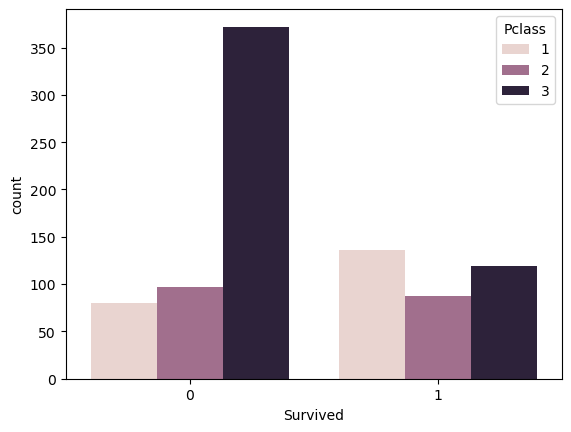

In [59]:
sns.countplot(data=df_train, x='Survived', hue='Pclass')

It appears that there are proportionally more survivors from first class, and fewer from third class.

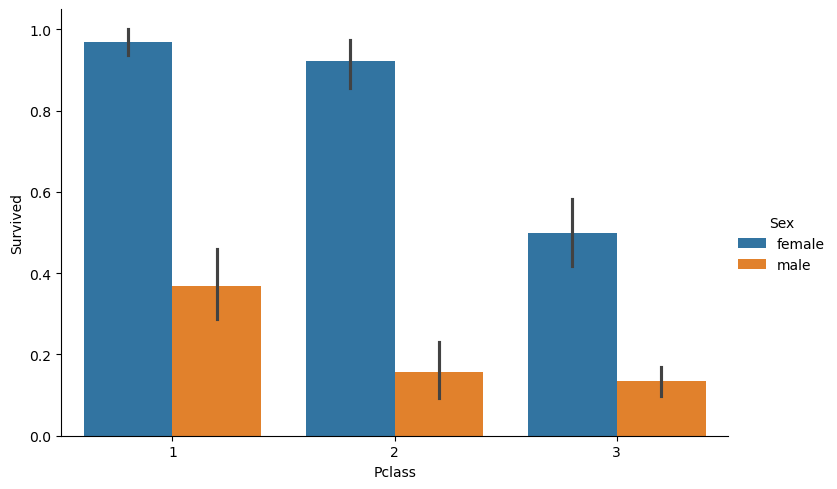

In [60]:
sns.catplot(
    data=df_train,
    x="Pclass",
    y="Survived",
    hue="Sex",
    kind="bar",
    height=5,
    aspect=1.5
)

In [61]:
df_train.pivot_table(
    values='Survived',
    index='Sex',
    columns='Pclass',
    aggfunc='mean'
)

Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [62]:
df_train.pivot_table(
    values='Survived',
    index='Sex',
    columns='Pclass',
    aggfunc='sum'
)

Pclass,1,2,3
Sex,,,
female,91,70,72
male,45,17,47


We also see that prediction will not be terribly difficult: the proportion of survivors is very high with first and second class female passengers and very low for male second and third class passenegers. Using rules capturing these patterns already accounts for a good recall/precision.

## Data preparation

Now we will start pre-processing the data. Firstly, let's have a look at the different variable types as these are important for our feature engineering. There are both integers (`int64`), floating point numbers (`float64`), and string-based/categorical variables (`object`) present. The non-numeric ones will have to be converted for most algorithms available (although strictly speaking some algorithms such as decision trees can cope with categorical variables, the implementation is not supporting this). We hence first request the data types through the `dtypes` attribute of the dataframe:

In [63]:
df_train.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Firstly, we remove the variables with unique values, or too many specific values which won't be able to add value to a classification exercise. In this particular case, we remove the ID, name, cabin number, and ticket number:

In [64]:
df_train_clean_1 = df_train.drop(['Name', 'PassengerId', 'Cabin', 'Ticket'], axis=1)
df_test_clean_1 = df_test.drop(['Name', 'PassengerId', 'Cabin', 'Ticket'], axis=1)

We also see that 'Pclass' is considered an integer and not a categorical variable, although class 1 is not 'better' than class 3 perhaps. Although one can reason that the lower the class number does have an ordinal interpretation. The following step to convert the class into a categorical variable is optional (remove hash signs to run code):

In [65]:
#print(df_train_clean_1['Pclass'])
#df_train_clean_1['Pclass'] = df_train_clean_1['Pclass'].astype('object')
#df_test_clean_1['Pclass'] = df_test_clean_1['Pclass'].astype('object')
#print(df_train_clean_1['Pclass'])

Let's visualise the distributions of the variables and see whether there are any troublesome correlations present:

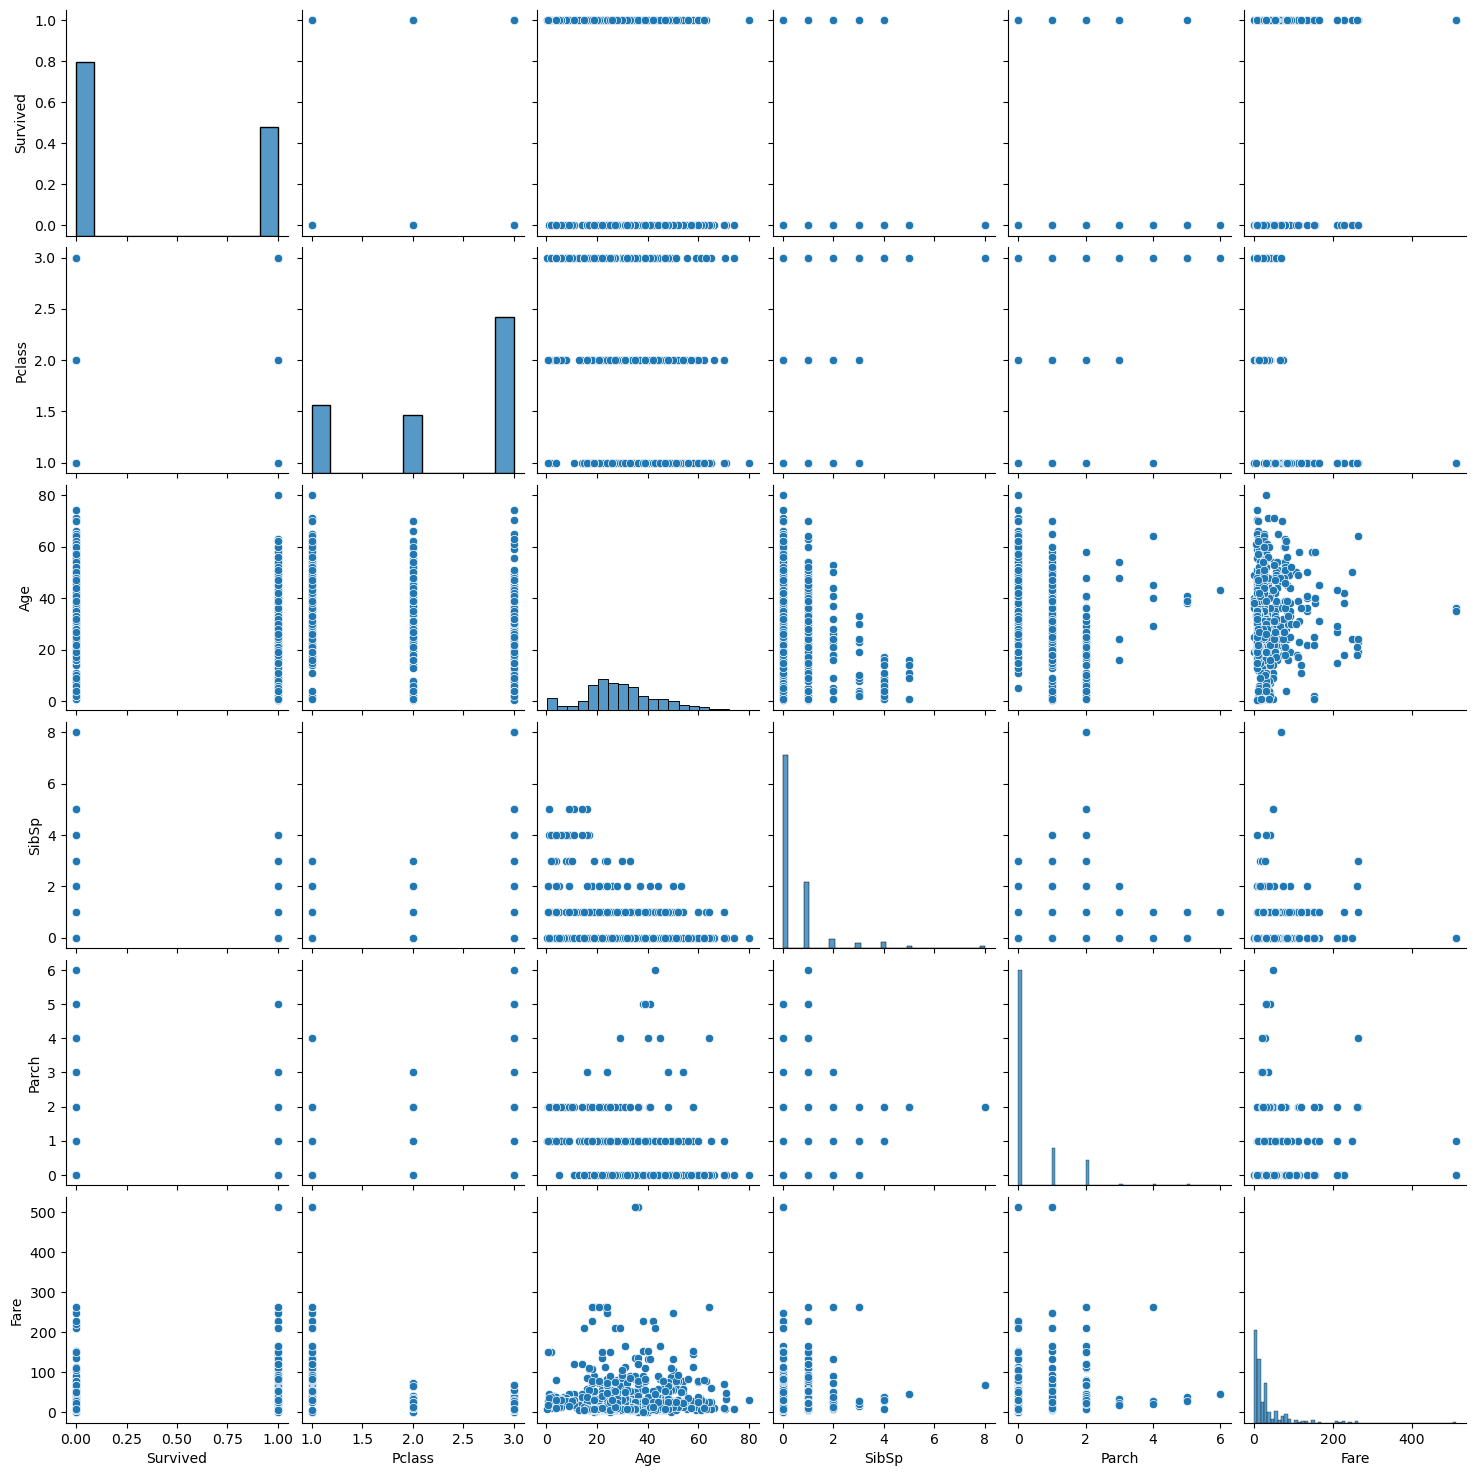

In [66]:
sns.pairplot(df_train_clean_1)

Given the high amount of categorical variables, there are few takeaways, but this figure can be handy for datasets with many numeric variables.

Finally, we also construct a heatmap of the correlations:

<Axes: >

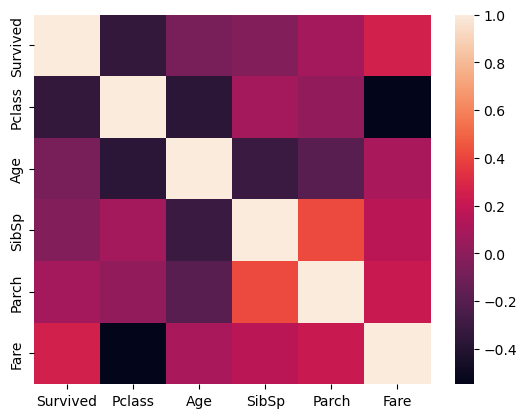

In [67]:
sns.heatmap(data=df_train_clean_1.corr(numeric_only=True))

Perhaps it might be wise to remove some correlated features, such as 'Pclass' and 'Fare', or 'Age', and 'Pclass'. For this exercise, we will not for simplicity's sake.

### Missing data

Missing data can cause algorithms not to work. We typically have to address this is some form or another. Below we will both look into removing the lines of data which contain empty cells (typically stored as `Na` or `NaN` which stands for, perhaps confusingly, 'not a number') and imputing the empty cells with the mean per column. We can check this per column:

In [68]:
for column in df_train_clean_1.columns:
  print('Column:', column)
  print(df_train_clean_1[column].isna().sum())

Column: Survived
0
Column: Pclass
0
Column: Sex
0
Column: Age
177
Column: SibSp
0
Column: Parch
0
Column: Fare
0
Column: Embarked
2


We do have some missing values. The age can be imputed with the mean easily, as it is numeric. For the 'Embarked' column, which is categorical, it might not be so straightforward. Hence, we will first impute the age with the mean and then remove the remaining columns.

#### Imputation

Removal can be practical, but sometimes we don't want to remove all the other values on the line just because 1 cell is empty. In this case, we can consider imputing a value such as the mean, median, or even build a whole supervised model to impute the value. Below, we will impute the mean by both using Pandas. Given we will use imputation to continue, we now also involve our test set. In order to have no data leakage, the imputation on the test set needs to be performed with the parameter (in this case the mean) obtained from the training set.

In [69]:
df_train_clean_1['Age'].mean()

np.float64(29.69911764705882)

In [70]:
# we first calculate the mean age of the training set
mean_age_training = df_train_clean_1['Age'].mean()
# we use function .fillna() with argument 'inplace' to indicate
# we want to fill the empty cells
df_train_clean_1['Age'].fillna(mean_age_training, inplace = True)
df_test_clean_1['Age'].fillna(mean_age_training, inplace = True)

for column in df_train_clean_1.columns:
  print('Column:', column)
  print(df_train_clean_1[column].isna().sum())

Column: Survived
0
Column: Pclass
0
Column: Sex
0
Column: Age
0
Column: SibSp
0
Column: Parch
0
Column: Fare
0
Column: Embarked
2


C:\Users\u0092789\AppData\Local\Temp\ipykernel_35464\1376646107.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train_clean_1['Age'].fillna(mean_age_training, inplace = True)
C:\Users\u0092789\AppData\Local\Temp\ipykernel_35464\1376646107.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beha

#### Removal

Now, we try removal for the remaining 2 rows. We can use the `dropna()` function which exists in Pandas. We then check whether the `NaN`s are gone:

In [71]:
df_train_clean_2 = df_train_clean_1.dropna()
df_test_clean_2 = df_test_clean_1.dropna()

for column in df_train_clean_2.columns:
  print('Column:', column)
  print(df_train_clean_2[column].isna().sum())

Column: Survived
0
Column: Pclass
0
Column: Sex
0
Column: Age
0
Column: SibSp
0
Column: Parch
0
Column: Fare
0
Column: Embarked
0


### Normalisation

One frequently used pre-processing step is standard or min-max normalisation. Given that we are using decision trees for which this is not strictly necessary, we will cover this is another notebook.

### Conversion/encoding

As mentioned before, most algorithmic implementations cannot deal with non-numeric variables. Hence, we need to convert the categorical variables still. We will do this using one-hot encoding to obtain a 0/1 representation of the different levels/values of the variable. The Pandas `get_dummies()` function allows to do this for all variables of type 'object' at once (in this case 'Embarked' and 'Sex').

In [72]:
df_train_clean_3 = pd.get_dummies(df_train_clean_2, drop_first=True)
df_test_clean_3 = pd.get_dummies(df_test_clean_2, drop_first=True)

df_train_clean_3

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.000000,1,0,7.2500,True,False,True
1,1,1,38.000000,1,0,71.2833,False,False,False
2,1,3,26.000000,0,0,7.9250,False,False,True
3,1,1,35.000000,1,0,53.1000,False,False,True
4,0,3,35.000000,0,0,8.0500,True,False,True
...,...,...,...,...,...,...,...,...,...
886,0,2,27.000000,0,0,13.0000,True,False,True
887,1,1,19.000000,0,0,30.0000,False,False,True
888,0,3,29.699118,1,2,23.4500,False,False,True
889,1,1,26.000000,0,0,30.0000,True,False,False


In [73]:
df_test_clean_3

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,34.500000,0,0,7.8292,True,True,False
1,3,47.000000,1,0,7.0000,False,False,True
2,2,62.000000,0,0,9.6875,True,True,False
3,3,27.000000,0,0,8.6625,True,False,True
4,3,22.000000,1,1,12.2875,False,False,True
...,...,...,...,...,...,...,...,...
413,3,29.699118,0,0,8.0500,True,False,True
414,1,39.000000,0,0,108.9000,False,False,False
415,3,38.500000,0,0,7.2500,True,False,True
416,3,29.699118,0,0,8.0500,True,False,True


Notice how columns 'Embarked_C', 'Embarked_Q', and 'Embarked_S' and 'Sex_female' and 'Sex_male' are added to the dataframe.

## Building a simple decision tree

Now we can finally build the classfication model. We use a simple decision tree which, by default in the scikit-learn package, is based on the Gini index and follows the CART (Classification And Regression Tree) algorithm. We first split the dependent variable off into a separate dataframe, which is required for the implementation:

In [74]:
# we only keep the dependent variable in de _y part
df_train_y = df_train_clean_3['Survived']
# we remove the label from the independent _X part
df_train_X = df_train_clean_3.drop(['Survived'], axis=1)

Next, we can fit the training data. In order to avoid a massive (and probably overfitting tree), we limit the maximum depth of the tree to 3 and don't create leaves with fewer than 10 samples. We can do this using the arguments of the `DecisionTreeClassifier` object we create. For a full overview of its arguments, you can consult the documentation here: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

In [75]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dt_one = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10)
# we fit the decision tree on the training data, the results (i.e. the tree)
# is stored in the 'dt_one' object
dt_one.fit(df_train_X, df_train_y)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### Visualisation

Once we have created the tree, we can visualise it using the following code. If you ever need it I suggest you mostly copy this code and just change the decision tree variable (`dt_one`) if necessary and/or the data used (`df_train_`) and the class names. Besides that, it is mostly plug-and-play.

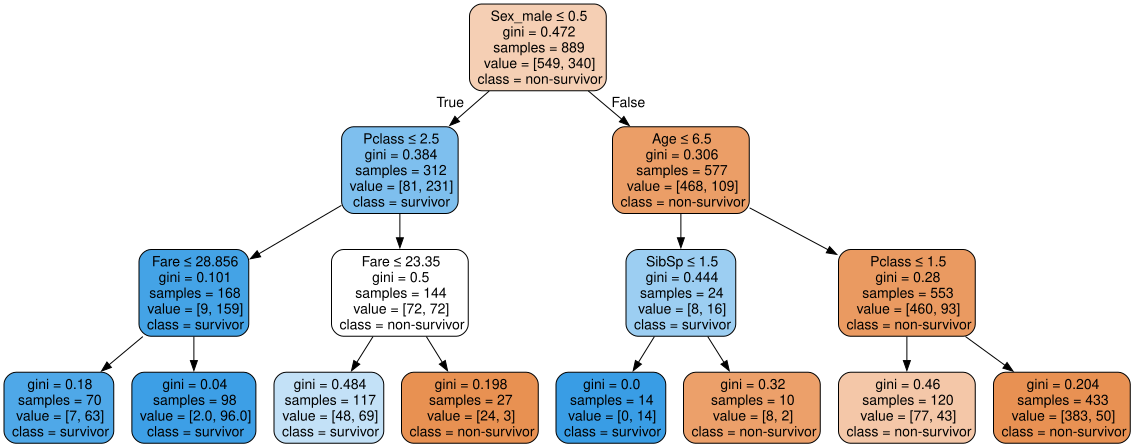

<Figure size 100x100 with 0 Axes>

In [76]:
import matplotlib.pyplot as plt
import graphviz
from sklearn.tree import export_graphviz

plt.figure(figsize=(1,1))
dot_data = export_graphviz(dt_one, out_file=None,
     feature_names=df_train_X.columns,  class_names=['non-survivor', 'survivor'],
                     filled=True, rounded=True,
                     special_characters=True)
graph = graphviz.Source(dot_data)
graph

The tree is relatively compact and easy to interpret. Per node, we can see the number of samples present, the class distribution (in the top node: [549, 340] non-survivor vs. survivor). It also notes what the (majority) prediction in that node is. The blue nodes contain more surviving than non-surviving observations.

It appears that being male already gives you a severe disadvantage towards survival. Next, we see that on the left side, the passenger class and fare (which are correlated, could have addressed this as decision trees are very susceptible to collinearity) determine your chance towards survival. The lower your class and the higher the fare, the better. On the left side, we see that female passengers' age, number of siblings, and again passenger class help determine whether someone survived yes/no.

### Evaluation

In order to evaluate this outcome, we will now use the decision tree to predict the labels of the training set instances to gauge the accuracy, as we lack the real labels of the test set. It is not ideal, but the Titanic dataset is a great way to get to know predictive analytics.
The test set will be used in the second notebook for evaluation, however.

Prediction happens with the `predict()` function. The predictions obtained are binary, just like the label. We can also obtain the probability per class label using `predict_proba()`, which we will use to calculate the area under receiver operating characteristics curve (AUC) below.

In [77]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

predictions = dt_one.predict(df_train_X)
predictions_prob = dt_one.predict_proba(df_train_X)
print('Predicted labels:', predictions)
print('Predicted probabilities:', predictions_prob)

print("Precision: %.3f" % precision_score(df_train_y, predictions))
print("Recall: %.3f" % recall_score(df_train_y, predictions))
# We use the second column of the predicted probabilities as this column contains
# the probabilities of someone surviving (the positive label)
print("AUC: %.3f" % roc_auc_score(df_train_y, predictions_prob[:,1]))

Predicted labels: [0 1 1 1 0 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0 0 0
 0 1 1 1 1 0 1 1 0 0 1 0 1 0 0 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0
 0 0 0 1 1 0 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 1
 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 1 0 0 0 1 1 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0
 1 0 0 0 1 0 1 1 1 1 0 0 1 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 1 1 0 0 0 1 0 0 1 1 1 1 1 1
 0 0 0 0 1 0 0 0 1 1 0 0 1 0 1 1 1 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 1 0 0 0
 1 0 1 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 1 0 1 1 1 1 0 0 0
 1 0 0 1 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 0 0 1 1 1 1 0
 0 0 0 1 1 1 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 1 1 0 1 0 0 1 0 0 1 0 1 0 0 1
 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 1 0 0 1 0 0 1 0
 1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 0 0
 0 1 0 

It appears our precision (predicting who will survive) is better than our overall prediction as measured by the recall. Given that the dataset is unbalanced (more non-survivors than survivors), the AUC is more appropriate as we don't assume survival is a 50% chance but vary the classification threshold. The AUC is quite high at 86%, so our tree does a good job on the training data. We can visualise this with the ROC curve:

Text(0, 0.5, 'True Positive Rate (TPR)')

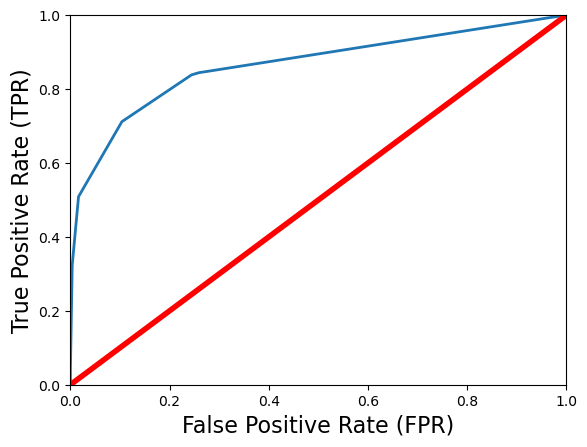

In [78]:
from sklearn.metrics import roc_curve

false_positive_rate, true_positive_rate, thresholds = roc_curve(df_train_y, predictions_prob[:,1])

plt.plot(false_positive_rate, true_positive_rate, linewidth=2)
plt.plot([0, 1], [0, 1], 'r', linewidth=4)
plt.axis([0, 1, 0, 1])
plt.xlabel('False Positive Rate (FPR)', fontsize=16)
plt.ylabel('True Positive Rate (TPR)', fontsize=16)

We can't evaluate it due to missing labels, we can still make a prediction for our unseen test data as follows:

In [79]:
from sklearn.metrics import confusion_matrix

predictions = dt_one.predict(df_test_clean_3)
number_of_survivors_predicted_test = np.sum(predictions)
print('Number of survivors predicted:', number_of_survivors_predicted_test, 'out of', len(predictions), 'observations')

Number of survivors predicted: 152 out of 417 observations
